# Lab: Comparing Distributions Across Groups

Choose a new documented dataset with **at least one categorical feature and three quantitative features**. Develop and answer **three distinct research questions**, each comparing the distribution of a different quantitative feature across categorical groups. Use the six-step reproducible analysis workflow for each question, as in the Billboard lecture.

Your dataset must not have been used in any class demonstration or lab, including your own earlier lab submissions.


## Learning goals

- Select and document a new dataset suitable for comparing distributions.
- Distinguish meaningful quantitative measurements from identifiers and category codes.
- Develop three questions and record predictions before analyzing their results.
- Compare group sizes, center, spread, shape, overlap, and unusual observations.
- Check calculations against original records and write supported conclusions and limitations.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context? Do original records support the calculation and interpretation?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete all six steps separately for each question. Inspect the dataset once, then explain the observations, features, and preparation relevant to each investigation. Use separate code cells for individual operations and add cells as needed.


## Using AI tools responsibly

You may use AI for questions, debugging, or feedback. You remain responsible for understanding the code, reading the actual source documentation, and checking claims against your output. Disclose AI use and describe a suggestion you checked in the final reflection.


## Find and document a new dataset

Choose a manageable CSV from a documented source, such as a government open-data portal, a research repository, or Kaggle. It must have:

- A named publisher or creator and a data dictionary or equivalent feature documentation.
- At least one meaningful categorical feature with two or more groups containing multiple observations.
- At least three distinct quantitative measurements with documented meanings and units. Numeric IDs, category codes, and alternate-unit copies of the same measurement do not count as three quantitative features.
- Enough usable observations in each comparison group to examine distributions. There is no universal minimum group size for this descriptive exercise; justify exclusions and acknowledge sparse groups.
- A topic and dataset that have not already been used in class or any lab. A different filename, subset, or download of a previously used dataset does not make it new.

Review the course notebooks and your previous submissions. Examples already used include Billboard number-one songs, Titanic passengers, Pokémon, and penguins; this is not an exhaustive list.

Save the CSV in this notebook's `data` folder, use a relative path, and preserve the original records. Use a descriptive DataFrame name ending in `_df`. Your categorical feature can be reused across questions, or you may choose different categorical features for different questions.


**What are the dataset title, publisher or creator, direct source URL, data dictionary URL or location, and access date?**

Your answer:

Dataset: Iris (Iris Plants Database), credited to R. A. Fisher (1936), distributed by the UCI Machine Learning Repository. [Dataset and feature dictionary](https://archive.ics.uci.edu/dataset/53/iris). [Direct comma-separated data](https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data). [Original dictionary](https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.names), also saved as `data/iris.names`. Accessed October 13, 2026. The data are supplied under CC BY 4.0. The headerless original is saved byte-for-byte as `data/iris.csv`.

**Describe the dataset: what does one row represent, what time period and population or location does it cover, and how were observations collected? State when something is undocumented.**

Your answer:

One row represents an iris plant with four flower measurements in centimeters and a species label. There are 150 plants, 50 per species. This historical dataset is associated with Fisher’s 1936 work. The supplied dictionary does not give a complete sampling protocol, collection dates, or a location for every record; 1936 is a publication association, not an assumed measurement date. These are measured plant traits, not an experiment that randomly assigns species.

**How did you confirm this dataset has not been used in class or any earlier lab, including your own submissions?**

Your answer:

A search of the code and Markdown cells in the local course repository found no prior Iris dataset use. The visible earlier lab notebooks and course data filenames were also checked. This supports selecting Iris for this notebook, but submissions or class demonstrations outside this repository were unavailable; I need to confirm those did not use Iris before submitting.

## Load and inspect the data

Use separate cells to import the libraries, load the CSV, and inspect its structure. Identify special missing codes from the dictionary; distinguish them from valid zeros.


In [1]:
# Import Pandas, Matplotlib pyplot, and Seaborn with conventional aliases.

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# Load your CSV into a descriptive DataFrame ending in _df using a relative path.

iris_original_df = pd.read_csv(
    "data/iris.csv", header=None,
    names=["sepal_length_cm", "sepal_width_cm", "petal_length_cm", "petal_width_cm", "species"]
)


### Preserve the source and apply its documented corrections

UCI’s dictionary identifies discrepancies in records 35 and 38 (one-based). The original file and `iris_original_df` remain intact; only `iris_df` is corrected. The following cells show exactly what changes.

In [3]:
iris_df = iris_original_df.copy()
iris_df.loc[34, "petal_width_cm"] = 0.2
iris_df.loc[37, ["sepal_width_cm", "petal_length_cm"]] = [3.6, 1.4]
display(iris_original_df.loc[[34, 37]])
display(iris_df.loc[[34, 37]])

,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
34,4.9,3.1,1.5,0.1,Iris-setosa
37,4.9,3.1,1.5,0.1,Iris-setosa


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
34,4.9,3.1,1.5,0.2,Iris-setosa
37,4.9,3.6,1.4,0.1,Iris-setosa


In [4]:
# Keep species order and named colors consistent across all comparisons.
species_order = ["Iris-setosa", "Iris-versicolor", "Iris-virginica"]
species_colors = {"Iris-setosa": "steelblue", "Iris-versicolor": "darkorange", "Iris-virginica": "seagreen"}

In [5]:
# Display the first five rows.

iris_df.head()


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [6]:
# Display the last five rows.

iris_df.tail()


,sepal_length_cm,sepal_width_cm,petal_length_cm,petal_width_cm,species
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica
149,5.9,3.0,5.1,1.8,Iris-virginica


In [7]:
# Display the DataFrame shape.

iris_df.shape


(150, 5)

In [8]:
# Display .info().

iris_df.info()


<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   sepal_length_cm  150 non-null    float64
 1   sepal_width_cm   150 non-null    float64
 2   petal_length_cm  150 non-null    float64
 3   petal_width_cm   150 non-null    float64
 4   species          150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [9]:
# Display missing-value counts for every feature.

iris_df.isna().sum()


sepal_length_cm    0
sepal_width_cm     0
petal_length_cm    0
petal_width_cm     0
species            0
dtype: int64

### Document the features

Complete one row for **every feature**. Add rows as needed. For data type, use categorical or quantitative, and explicitly identify identifiers and temporal features where appropriate. Report the actual Pandas storage type separately.


| Feature | Meaning and units or category codes | Data type | Data storage type | Missing values |
| --- | --- | --- | --- | ---: |
| sepal_length_cm | Sepal length, cm | quantitative | float64 | 0 |
| sepal_width_cm | Sepal width, cm | quantitative | float64 | 0 |
| petal_length_cm | Petal length, cm | quantitative | float64 | 0 |
| petal_width_cm | Petal width, cm | quantitative | float64 | 0 |
| species | Iris-setosa, Iris-versicolor, Iris-virginica | categorical | str | 0 |

No identifiers or temporal features are provided. Older Pandas versions may report `object` rather than `str` for species.

**Which categorical feature(s) and three quantitative features will you analyze? Why are they appropriate for distribution comparisons? Explain any missing codes or conversions.**

Your answer:

Species supplies three comparison groups. The questions use sepal length, sepal width, and petal length, each in centimeters; these are distinct measurements, not IDs or alternate-unit copies. No special missing codes are documented and no missing values occur. No unit conversion is needed. Two source-documented record corrections are applied only to a separate analysis copy; no observations are removed. Fifty observations per group support descriptive comparisons, although the sample does not establish population-wide differences.

## Plan three investigations

Write three specific questions. **Use a different quantitative feature for each question**, covering at least three in total. Each question must compare that feature's distribution across at least two categorical groups. You may reuse the same grouping feature. Changing only the plot type does not create a new question.

A useful question pattern is: “How does the distribution of [measurement and units] differ among [groups] in [documented population or period]?” Adapt it to your dataset's meaning. Similar distributions are a valid result; do not search for differences by repeatedly changing groups or discarding records.


## Investigation 1

### Step 1: Question


**What is research question 1? Name the quantitative feature, its units, and the categorical groups.**

Your answer:

How does the distribution of sepal length (cm) differ among Iris-setosa, Iris-versicolor, and Iris-virginica in the 150-plant UCI Iris sample?

**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer:

The working prediction is that sepal-length distributions will overlap but have somewhat different centers, because related species may have different typical flower sizes. This is a proposed starting hypothesis for the assisted analysis, not a claim about a prediction recorded in an earlier submission.

### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer:

Use the corrected analysis copy, selecting species and sepal_length_cm. One observation remains one plant. Keep all three original species labels in the same order. Drop a row only if its species or this measurement is missing; none are, so all 150 plants remain, 50 per species. Retain valid extreme values. Units are centimeters and no conversions are used.

In [10]:
# Prepare this question's analysis DataFrame and preview the selected features.

sepal_length_df = iris_df[["species", "sepal_length_cm"]].dropna().copy()
sepal_length_df.head()


,species,sepal_length_cm
0,Iris-setosa,5.1
1,Iris-setosa,4.9
2,Iris-setosa,4.7
3,Iris-setosa,4.6
4,Iris-setosa,5.0


In [11]:
# Display the number of usable observations in each group.

sepal_length_df["species"].value_counts().reindex(species_order)


species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


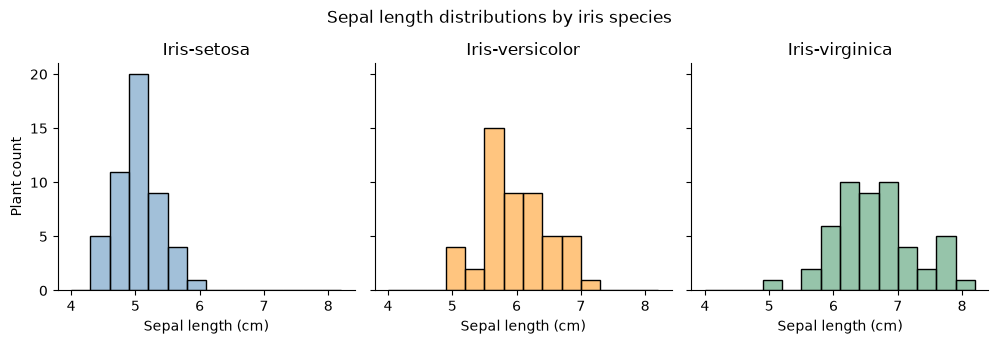

In [12]:
# Create and label the histogram comparison.

sns.displot(
    data=sepal_length_df, x="sepal_length_cm", hue="species", col="species",
    hue_order=species_order, col_order=species_order, palette=species_colors,
    bins=[4.0, 4.3, 4.6, 4.9, 5.2, 5.5, 5.8, 6.1, 6.4, 6.7, 7.0, 7.3, 7.6, 7.9, 8.2], stat="count", height=3.2, aspect=1.05, legend=False
)
plt.suptitle("Sepal length distributions by iris species", y=1.06)
plt.gcf().axes[0].set_ylabel("Plant count")
for ax in plt.gcf().axes:
    ax.set_xlabel("Sepal length (cm)")
    ax.set_title(ax.get_title().replace("species = ", ""))
plt.show()


**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer:

Setosa is concentrated near 5 cm, versicolor near 6 cm, and virginica around 6.5 cm. Setosa has the narrowest visible spread. Each distribution has one broad main concentration with some uneven bins; virginica has a longer high-value reach. The distributions overlap substantially, especially versicolor and virginica. Each group contains 50 plants, so differences in histogram heights are not caused by unequal group sizes. All panels use the same bins and axis scales.

In [13]:
# Display grouped .describe() summaries and calculate or display the IQR for each group.

sepal_length_summary = sepal_length_df.groupby("species")["sepal_length_cm"].describe().reindex(species_order)
sepal_length_summary["IQR"] = sepal_length_summary["75%"] - sepal_length_summary["25%"]
sepal_length_summary.round(3)


,count,mean,std,min,25%,50%,75%,max,IQR
species,,,,,,,,,
Iris-setosa,50.0,5.006,0.352,4.3,4.800,5.0,5.2,5.8,0.400
Iris-versicolor,50.0,5.936,0.516,4.9,5.600,5.9,6.3,7.0,0.700
Iris-virginica,50.0,6.588,0.636,4.9,6.225,6.5,6.9,7.9,0.675


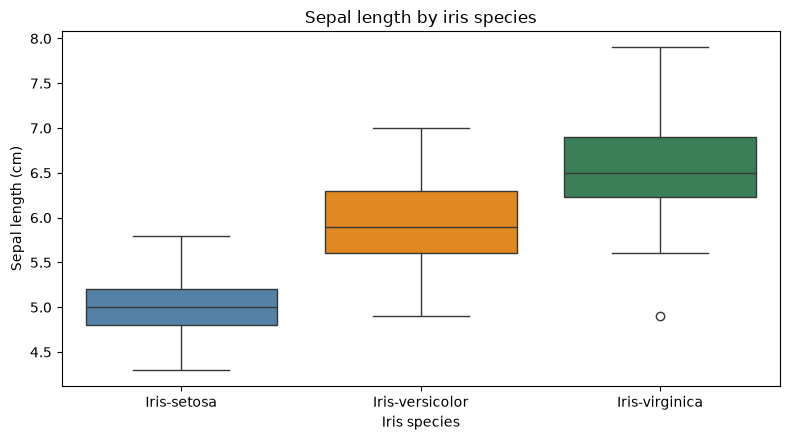

In [14]:
# Create and label the box-plot comparison.

plt.figure(figsize=(8, 4.5))
sns.boxplot(
    data=sepal_length_df, x="species", y="sepal_length_cm", order=species_order,
    hue="species", hue_order=species_order, palette=species_colors,
    legend=False
)
plt.title("Sepal length by iris species")
plt.xlabel("Iris species")
plt.ylabel("Sepal length (cm)")
plt.tight_layout()
plt.show()


**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer:

The summaries support the approximate histogram centers: setosa: median 5.00 cm, IQR 0.40 cm, range 4.3–5.8 cm; versicolor: median 5.90 cm, IQR 0.70 cm, range 4.9–7.0 cm; virginica: median 6.50 cm, IQR 0.68 cm, range 4.9–7.9 cm. The box plots show exact medians and middle-50% intervals, while histograms show the distribution shape and where observations concentrate. Box-plot points beyond the whiskers are flagged observations, not automatically errors. Neither plot alone explains why the groups differ.

### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [15]:
# Perform a targeted check against original records or the declared group definitions.

# Inspect the smallest and largest values in every group against the source rows.
sepal_length_extreme_rows = list(sepal_length_df.groupby("species")["sepal_length_cm"].idxmin()) + list(sepal_length_df.groupby("species")["sepal_length_cm"].idxmax())
display(iris_original_df.loc[sepal_length_extreme_rows, ["species", "sepal_length_cm"]])
print("Analyzed rows:", len(sepal_length_df))
print("Sum of group counts:", sepal_length_df.groupby("species").size().sum())
print("Zero or negative measurements:", (sepal_length_df["sepal_length_cm"] <= 0).sum())
assert len(sepal_length_df) == 150
assert sepal_length_df.groupby("species").size().eq(50).all()
assert (sepal_length_df["sepal_length_cm"] > 0).all()


,species,sepal_length_cm
13,Iris-setosa,4.3
57,Iris-versicolor,4.9
106,Iris-virginica,4.9
14,Iris-setosa,5.8
50,Iris-versicolor,7.0
131,Iris-virginica,7.9


Analyzed rows: 150
Sum of group counts: 150
Zero or negative measurements: 0


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer:

Zero or negative sepal length, values on a meter rather than centimeter scale, unexpected species labels, or group counts that do not add to 150 would be suspicious. The original-record extrema agree with the analyzed ranges; the group counts sum to 150, with 50 in each group and no nonpositive values. The plots cover those ranges. The source’s two documented corrections were checked separately and are retained only in the analysis copy. The remaining uncertainty is the incompletely documented sampling and measurement procedure; extreme values are retained.

### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer:

With 50 plants in each species, setosa: median 5.00 cm, IQR 0.40 cm, range 4.3–5.8 cm; versicolor: median 5.90 cm, IQR 0.70 cm, range 4.9–7.0 cm; virginica: median 6.50 cm, IQR 0.68 cm, range 4.9–7.9 cm. The ordering of the centers is setosa < versicolor < virginica, but the ranges overlap. The starting prediction of overlap and differing centers is supported.

### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer:

Overlapping sepal lengths cannot uniquely identify species. The balanced historical sample does not represent how common the species are in nature, and the source does not establish random sampling.

## Investigation 2

### Step 1: Question


**What is research question 2? Name the quantitative feature, its units, and the categorical groups.**

Your answer:

How does the distribution of sepal width (cm) differ among Iris-setosa, Iris-versicolor, and Iris-virginica in the 150-plant UCI Iris sample?

**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer:

The working prediction is substantial overlap in sepal width, since all three groups are related flowering plants and width alone may not distinguish them. There is no strong directional prediction about which species will be widest.

### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer:

Use the corrected analysis copy, selecting species and sepal_width_cm. One observation remains one plant. Keep all three original species labels in the same order. Drop a row only if its species or this measurement is missing; none are, so all 150 plants remain, 50 per species. Retain valid extreme values. Units are centimeters and no conversions are used.

In [16]:
# Prepare this question's analysis DataFrame and preview the selected features.

sepal_width_df = iris_df[["species", "sepal_width_cm"]].dropna().copy()
sepal_width_df.head()


,species,sepal_width_cm
0,Iris-setosa,3.5
1,Iris-setosa,3.0
2,Iris-setosa,3.2
3,Iris-setosa,3.1
4,Iris-setosa,3.6


In [17]:
# Display the number of usable observations in each group.

sepal_width_df["species"].value_counts().reindex(species_order)


species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


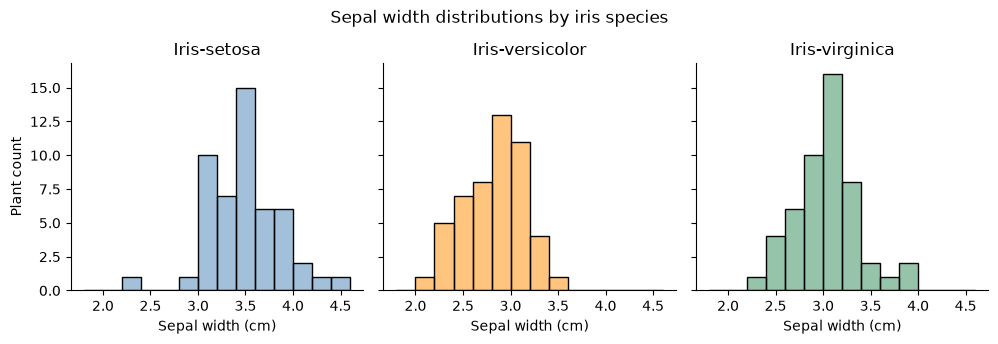

In [18]:
# Create and label the histogram comparison.

sns.displot(
    data=sepal_width_df, x="sepal_width_cm", hue="species", col="species",
    hue_order=species_order, col_order=species_order, palette=species_colors,
    bins=[1.8, 2.0, 2.2, 2.4, 2.6, 2.8, 3.0, 3.2, 3.4, 3.6, 3.8, 4.0, 4.2, 4.4, 4.6], stat="count", height=3.2, aspect=1.05, legend=False
)
plt.suptitle("Sepal width distributions by iris species", y=1.06)
plt.gcf().axes[0].set_ylabel("Plant count")
for ax in plt.gcf().axes:
    ax.set_xlabel("Sepal width (cm)")
    ax.set_title(ax.get_title().replace("species = ", ""))
plt.show()


**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer:

Setosa is concentrated around 3.4 cm, versicolor around 2.8 cm, and virginica around 3.0 cm. All have one broad main concentration and considerable overlap. Setosa has a wider span, including observations near 2.3 and 4.4 cm; the histograms do not establish perfectly symmetric or normal distributions. Each group contains 50 plants, so differences in histogram heights are not caused by unequal group sizes. All panels use the same bins and axis scales.

In [19]:
# Display grouped .describe() summaries and calculate or display the IQR for each group.

sepal_width_summary = sepal_width_df.groupby("species")["sepal_width_cm"].describe().reindex(species_order)
sepal_width_summary["IQR"] = sepal_width_summary["75%"] - sepal_width_summary["25%"]
sepal_width_summary.round(3)


,count,mean,std,min,25%,50%,75%,max,IQR
species,,,,,,,,,
Iris-setosa,50.0,3.428,0.379,2.3,3.200,3.4,3.675,4.4,0.475
Iris-versicolor,50.0,2.770,0.314,2.0,2.525,2.8,3.000,3.4,0.475
Iris-virginica,50.0,2.974,0.322,2.2,2.800,3.0,3.175,3.8,0.375


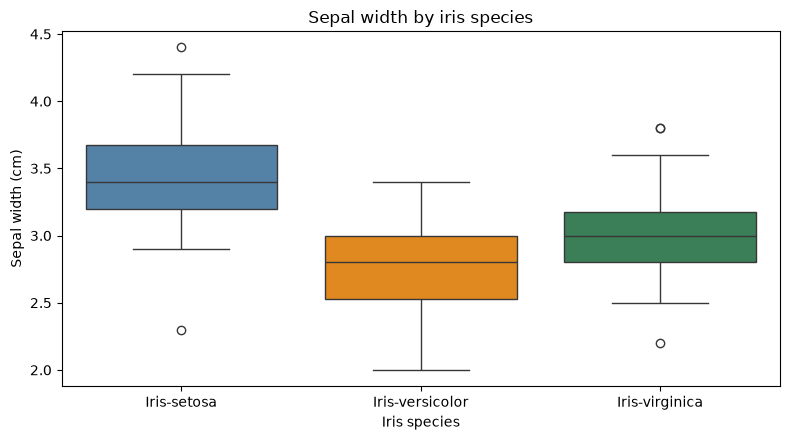

In [20]:
# Create and label the box-plot comparison.

plt.figure(figsize=(8, 4.5))
sns.boxplot(
    data=sepal_width_df, x="species", y="sepal_width_cm", order=species_order,
    hue="species", hue_order=species_order, palette=species_colors,
    legend=False
)
plt.title("Sepal width by iris species")
plt.xlabel("Iris species")
plt.ylabel("Sepal width (cm)")
plt.tight_layout()
plt.show()


**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer:

The summaries support the approximate histogram centers: setosa: median 3.40 cm, IQR 0.48 cm, range 2.3–4.4 cm; versicolor: median 2.80 cm, IQR 0.48 cm, range 2.0–3.4 cm; virginica: median 3.00 cm, IQR 0.38 cm, range 2.2–3.8 cm. The box plots show exact medians and middle-50% intervals, while histograms show the distribution shape and where observations concentrate. Box-plot points beyond the whiskers are flagged observations, not automatically errors. Neither plot alone explains why the groups differ.

### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [21]:
# Perform a targeted check against original records or the declared group definitions.

# Inspect the smallest and largest values in every group against the source rows.
sepal_width_extreme_rows = list(sepal_width_df.groupby("species")["sepal_width_cm"].idxmin()) + list(sepal_width_df.groupby("species")["sepal_width_cm"].idxmax())
display(iris_original_df.loc[sepal_width_extreme_rows, ["species", "sepal_width_cm"]])
print("Analyzed rows:", len(sepal_width_df))
print("Sum of group counts:", sepal_width_df.groupby("species").size().sum())
print("Zero or negative measurements:", (sepal_width_df["sepal_width_cm"] <= 0).sum())
assert len(sepal_width_df) == 150
assert sepal_width_df.groupby("species").size().eq(50).all()
assert (sepal_width_df["sepal_width_cm"] > 0).all()


,species,sepal_width_cm
41,Iris-setosa,2.3
60,Iris-versicolor,2.0
119,Iris-virginica,2.2
15,Iris-setosa,4.4
85,Iris-versicolor,3.4
117,Iris-virginica,3.8


Analyzed rows: 150
Sum of group counts: 150
Zero or negative measurements: 0


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer:

Zero or negative sepal width, values on a meter rather than centimeter scale, unexpected species labels, or group counts that do not add to 150 would be suspicious. The original-record extrema agree with the analyzed ranges; the group counts sum to 150, with 50 in each group and no nonpositive values. The plots cover those ranges. The source’s two documented corrections were checked separately and are retained only in the analysis copy. The remaining uncertainty is the incompletely documented sampling and measurement procedure; extreme values are retained.

### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer:

With 50 plants in each species, setosa: median 3.40 cm, IQR 0.48 cm, range 2.3–4.4 cm; versicolor: median 2.80 cm, IQR 0.48 cm, range 2.0–3.4 cm; virginica: median 3.00 cm, IQR 0.38 cm, range 2.2–3.8 cm. Setosa has the largest median width, followed by virginica and versicolor. All three ranges overlap. Versicolor and virginica also overlap in their middle-50% intervals; setosa’s middle-50% interval is just above virginica’s. The prediction of substantial overall overlap is supported.

### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer:

Sepal-width overlap is large, so a plant with a width near 3 cm cannot be confidently assigned a species from this measurement alone. The historical records have documented corrections, and the precision and collection conditions are not fully described.

## Investigation 3

### Step 1: Question


**What is research question 3? Name the quantitative feature, its units, and the categorical groups.**

Your answer:

How does the distribution of petal length (cm) differ among Iris-setosa, Iris-versicolor, and Iris-virginica in the 150-plant UCI Iris sample?

**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer:

The working prediction is that petal length will vary among species, with some overlap, because petals are a visible flower characteristic that can differ between species. I do not assume complete separation before viewing the evidence.

### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer:

Use the corrected analysis copy, selecting species and petal_length_cm. One observation remains one plant. Keep all three original species labels in the same order. Drop a row only if its species or this measurement is missing; none are, so all 150 plants remain, 50 per species. Retain valid extreme values. Units are centimeters and no conversions are used.

In [22]:
# Prepare this question's analysis DataFrame and preview the selected features.

petal_length_df = iris_df[["species", "petal_length_cm"]].dropna().copy()
petal_length_df.head()


,species,petal_length_cm
0,Iris-setosa,1.4
1,Iris-setosa,1.4
2,Iris-setosa,1.3
3,Iris-setosa,1.5
4,Iris-setosa,1.4


In [23]:
# Display the number of usable observations in each group.

petal_length_df["species"].value_counts().reindex(species_order)


species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


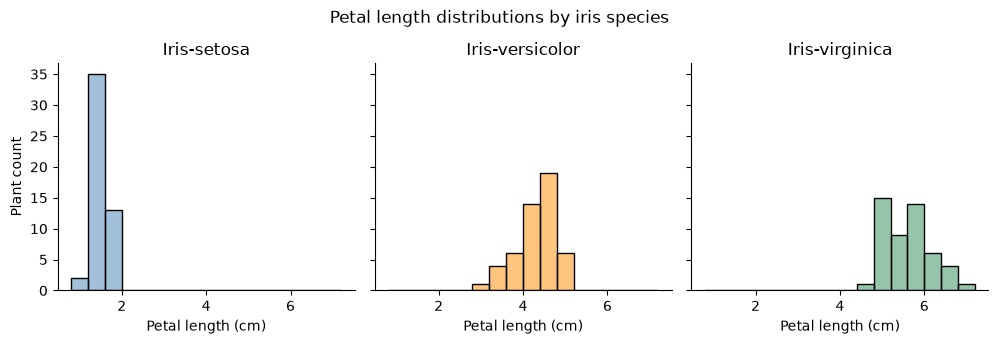

In [24]:
# Create and label the histogram comparison.

sns.displot(
    data=petal_length_df, x="petal_length_cm", hue="species", col="species",
    hue_order=species_order, col_order=species_order, palette=species_colors,
    bins=[0.8, 1.2, 1.6, 2.0, 2.4, 2.8, 3.2, 3.6, 4.0, 4.4, 4.8, 5.2, 5.6, 6.0, 6.4, 6.8, 7.2], stat="count", height=3.2, aspect=1.05, legend=False
)
plt.suptitle("Petal length distributions by iris species", y=1.06)
plt.gcf().axes[0].set_ylabel("Plant count")
for ax in plt.gcf().axes:
    ax.set_xlabel("Petal length (cm)")
    ax.set_title(ax.get_title().replace("species = ", ""))
plt.show()


**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer:

Setosa clusters near 1.5 cm in a very narrow range, versicolor around 4–5 cm, and virginica around 5–6 cm. Setosa is visually separated from the other species. Versicolor and virginica overlap; versicolor has a longer low-value tail, while virginica extends to nearly 7 cm. Bin choices affect the apparent bumps. Each group contains 50 plants, so differences in histogram heights are not caused by unequal group sizes. All panels use the same bins and axis scales.

In [25]:
# Display grouped .describe() summaries and calculate or display the IQR for each group.

petal_length_summary = petal_length_df.groupby("species")["petal_length_cm"].describe().reindex(species_order)
petal_length_summary["IQR"] = petal_length_summary["75%"] - petal_length_summary["25%"]
petal_length_summary.round(3)


,count,mean,std,min,25%,50%,75%,max,IQR
species,,,,,,,,,
Iris-setosa,50.0,1.462,0.174,1.0,1.4,1.50,1.575,1.9,0.175
Iris-versicolor,50.0,4.260,0.470,3.0,4.0,4.35,4.600,5.1,0.600
Iris-virginica,50.0,5.552,0.552,4.5,5.1,5.55,5.875,6.9,0.775


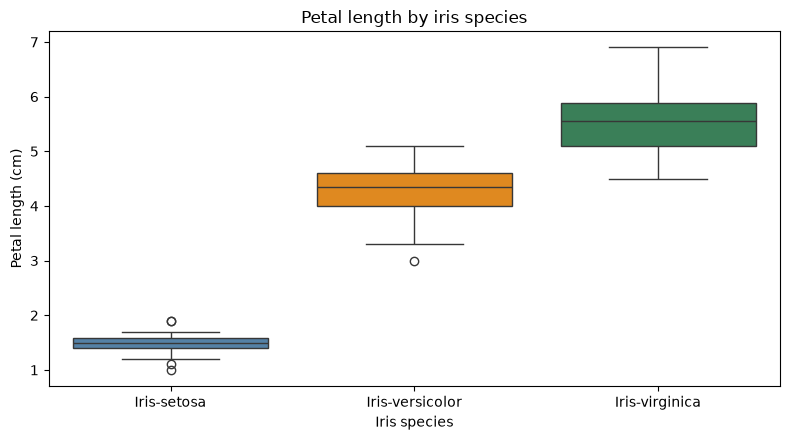

In [26]:
# Create and label the box-plot comparison.

plt.figure(figsize=(8, 4.5))
sns.boxplot(
    data=petal_length_df, x="species", y="petal_length_cm", order=species_order,
    hue="species", hue_order=species_order, palette=species_colors,
    legend=False
)
plt.title("Petal length by iris species")
plt.xlabel("Iris species")
plt.ylabel("Petal length (cm)")
plt.tight_layout()
plt.show()


**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer:

The summaries support the approximate histogram centers: setosa: median 1.50 cm, IQR 0.18 cm, range 1.0–1.9 cm; versicolor: median 4.35 cm, IQR 0.60 cm, range 3.0–5.1 cm; virginica: median 5.55 cm, IQR 0.78 cm, range 4.5–6.9 cm. The box plots show exact medians and middle-50% intervals, while histograms show the distribution shape and where observations concentrate. Box-plot points beyond the whiskers are flagged observations, not automatically errors. Neither plot alone explains why the groups differ.

### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [27]:
# Perform a targeted check against original records or the declared group definitions.

# Inspect the smallest and largest values in every group against the source rows.
petal_length_extreme_rows = list(petal_length_df.groupby("species")["petal_length_cm"].idxmin()) + list(petal_length_df.groupby("species")["petal_length_cm"].idxmax())
display(iris_original_df.loc[petal_length_extreme_rows, ["species", "petal_length_cm"]])
print("Analyzed rows:", len(petal_length_df))
print("Sum of group counts:", petal_length_df.groupby("species").size().sum())
print("Zero or negative measurements:", (petal_length_df["petal_length_cm"] <= 0).sum())
assert len(petal_length_df) == 150
assert petal_length_df.groupby("species").size().eq(50).all()
assert (petal_length_df["petal_length_cm"] > 0).all()


,species,petal_length_cm
22,Iris-setosa,1.0
98,Iris-versicolor,3.0
106,Iris-virginica,4.5
24,Iris-setosa,1.9
83,Iris-versicolor,5.1
118,Iris-virginica,6.9


Analyzed rows: 150
Sum of group counts: 150
Zero or negative measurements: 0


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer:

Zero or negative petal length, values on a meter rather than centimeter scale, unexpected species labels, or group counts that do not add to 150 would be suspicious. The original-record extrema agree with the analyzed ranges; the group counts sum to 150, with 50 in each group and no nonpositive values. The plots cover those ranges. The source’s two documented corrections were checked separately and are retained only in the analysis copy. The remaining uncertainty is the incompletely documented sampling and measurement procedure; extreme values are retained.

### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer:

With 50 plants in each species, setosa: median 1.50 cm, IQR 0.18 cm, range 1.0–1.9 cm; versicolor: median 4.35 cm, IQR 0.60 cm, range 3.0–5.1 cm; virginica: median 5.55 cm, IQR 0.78 cm, range 4.5–6.9 cm. Setosa has much shorter petals and a smaller IQR than either other group. Its maximum of 1.9 cm is below versicolor’s minimum of 3.0 cm. Versicolor and virginica overlap from 4.5 to 5.1 cm. Differences are stronger than the initial general prediction suggested.

### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer:

The separation of setosa in this sample does not prove that a universal threshold perfectly classifies future plants. Versicolor and virginica overlap, and no held-out prediction test or controlled causal comparison was performed.

## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer:

Yes. ChatGPT/Codex helped select the dataset, write code and draft interpretations, check source documentation, and run the notebook. A checked suggestion was to address UCI’s documented discrepancies: source row 35 has petal width 0.1 but the dictionary specifies 0.2; source row 38 has sepal width 3.1 and petal length 1.5 but the dictionary specifies 3.6 and 1.4. The analysis corrects those three cells in a copy and displays the original and corrected rows. The original CSV remains unchanged. The plotted medians and IQRs were checked against the summary tables. I should review this assisted analysis and confirm the dataset was not used outside the available repository before submitting.

## Submission checklist

- Include the new dataset CSV, source citation, dictionary reference, and explanation of why it has not been used in class or a previous lab.
- Document every feature, including meaning, units/codes, conceptual type, storage type, and missing count.
- Identify at least one categorical feature and three distinct quantitative features.
- Complete three different questions, one quantitative feature per question, each with a prediction and all six workflow steps.
- Include a histogram and box plot for each question, grouped summaries and IQRs, and usable group sizes.
- Explain preparation and exclusions; preserve valid extreme values and distinguish missing values from zero.
- Support conclusions about similarities or differences with numerical and visual evidence, contextual checks, and specific limitations.
- Complete every written response and the AI-use reflection.
- Restart the kernel and run every cell in order; use relative paths and ensure all claims match the output.
